In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ticker = "PLTR"

stock = yf.download(
    ticker,
    start="2021-10-01",
    end="2026-10-09",
    auto_adjust=False,
    progress=False
)

print(stock.shape)
print(stock.columns)
print(stock.index)
stock.head()

(1260, 6)
MultiIndex([('Adj Close', 'PLTR'),
            (    'Close', 'PLTR'),
            (     'High', 'PLTR'),
            (      'Low', 'PLTR'),
            (     'Open', 'PLTR'),
            (   'Volume', 'PLTR')],
           names=['Price', 'Ticker'])
DatetimeIndex(['2021-10-01', '2021-10-04', '2021-10-05', '2021-10-06',
               '2021-10-07', '2021-10-08', '2021-10-11', '2021-10-12',
               '2021-10-13', '2021-10-14',
               ...
               '2026-09-25', '2026-09-28', '2026-09-29', '2026-09-30',
               '2026-10-01', '2026-10-02', '2026-10-05', '2026-10-06',
               '2026-10-07', '2026-10-08'],
              dtype='datetime64[s]', name='Date', length=1260, freq=None)


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,PLTR,PLTR,PLTR,PLTR,PLTR,PLTR
Date,,,,,,
2021-10-01,24.330000,24.330000,24.360001,23.719999,24.209999,32778000
2021-10-04,23.170000,23.170000,24.049999,23.020000,24.010000,46789700
2021-10-05,23.209999,23.209999,23.879999,23.070000,23.209999,56574800
2021-10-06,23.580000,23.580000,25.010000,23.350000,24.910000,125175700
2021-10-07,23.730000,23.730000,24.129999,23.540001,23.709999,38873700


In [2]:
stock.columns = stock.columns.droplevel("Ticker")
print(stock.columns)
stock.head()

Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='str', name='Price')


Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2021-10-01,24.330000,24.330000,24.360001,23.719999,24.209999,32778000
2021-10-04,23.170000,23.170000,24.049999,23.020000,24.010000,46789700
2021-10-05,23.209999,23.209999,23.879999,23.070000,23.209999,56574800
2021-10-06,23.580000,23.580000,25.010000,23.350000,24.910000,125175700
2021-10-07,23.730000,23.730000,24.129999,23.540001,23.709999,38873700


In [3]:
## Checking if there is NAN value in columns
missing_by_columns = stock.isna().sum()
print(missing_by_columns)
print(missing_by_columns.sum())

## Check if duplicate dates
duplicate_count = stock.index.duplicated().sum()
print("Duplicate dates: ", duplicate_count)


Price
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64
0
Duplicate dates:  0


In [4]:
## Check if there are stock splits and dividends
pltr = yf.Ticker("PLTR")

splits = pltr.splits
dividens = pltr.dividends

print("Stock split: ")
print(splits)
print("\nStock dividends: ")
print(dividens)

price_difference = (stock["Close"] - stock["Adj Close"]).abs()
print("Maximum difference:", price_difference.max())


Stock split: 
Series([], Name: Stock Splits, dtype: object)

Stock dividends: 
Series([], Name: Dividends, dtype: object)
Maximum difference: 0.0


In [5]:
## Calculate log return 
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ticker = "PLTR"

stock = yf.download(
    ticker,
    start="2021-10-01",
    end="2026-10-09",
    auto_adjust=False,
    progress=False
)


prices = stock["Adj Close"].copy()
log_return = np.log(prices).diff().dropna()
print("Observations: ", len(log_return))
print(log_return.head())

split_index = int(len(log_return)*0.8)
print(split_index)

## 80% Calibration return / 20% validation return
calibration_return = log_return.iloc[:split_index]
validation_return = log_return.iloc[split_index:]
histrocial_volatility_benchmark = np.std(calibration_return, ddof=1)

## Historical return - GBM method constant volatility 
annualized_histrocial_volatility_benchmark = histrocial_volatility_benchmark*np.sqrt(252)
print(histrocial_volatility_benchmark)
print(annualized_histrocial_volatility_benchmark)
print(calibration_return.shape)
print(validation_return.shape)


Observations:  1259
Ticker          PLTR
Date                
2021-10-04 -0.048852
2021-10-05  0.001725
2021-10-06  0.015816
2021-10-07  0.006341
2021-10-08 -0.009740
1007
0.042385935836716064
0.6728558718641469
(1007, 1)
(252, 1)


## EWMA Volatility Estimation

EWMA recursively estimates conditional variance using past returns.
The decay factor lambda controls how quickly the model responds to new information.

0.9 (1007,) 0.5045842405654614
0.94 (1007,) 0.47405396643582515
0.97 (1007,) 0.49216325079276446


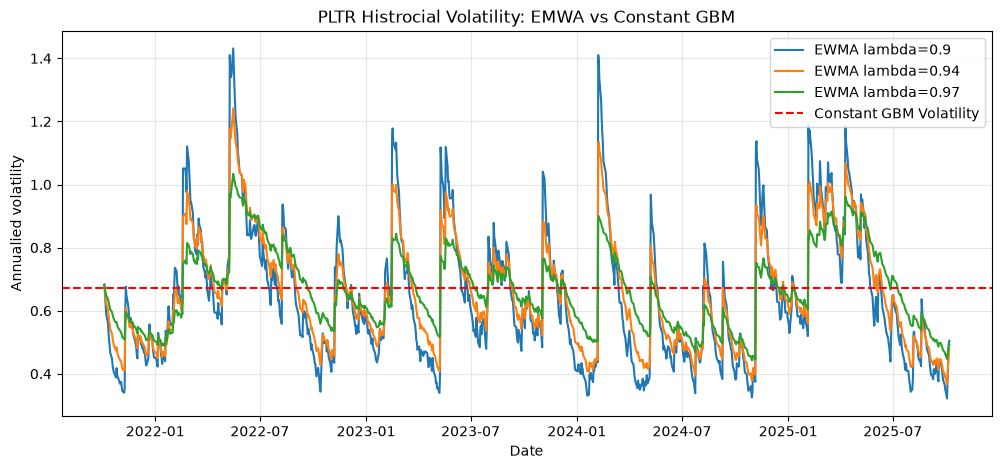

In [6]:
lambdas = [0.90, 0.94, 0.97]
ewma_result ={}

returns = calibration_return.to_numpy().flatten()
initial_variance = np.var(returns, ddof=1)

## create a same legnth array to contain ewma variance
for lam in lambdas:
    ewma_variance = np.zeros(len(returns))
    ewma_variance[0] = initial_variance

    for t in range(1, len(returns)):
        ewma_variance[t] = lam*ewma_variance[t-1] + (1-lam)*returns[t-1]**2

    ## Annualize volatility
    ewma_result[lam] = np.sqrt(252*ewma_variance)

for lam, vol in ewma_result.items():
    print(lam, vol.shape, vol[-1])


## Visualization
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))

for lam, vol in ewma_result.items():
    plt.plot(
        calibration_return.index,
        vol,
        label = f"EWMA lambda={lam}"
    )

## Add Constant GBM as benchmark
plt.axhline(
    y = annualized_histrocial_volatility_benchmark,
    color = "red",
    linestyle = "--",
    label = "Constant GBM Volatility"
)

plt.title("PLTR Histrocial Volatility: EMWA vs Constant GBM")
plt.xlabel("Date")
plt.ylabel("Annualied volatility")
plt.legend()
plt.grid(alpha =0.3)
plt.show()

In [7]:
## Calculate MSE for three lambdas
burn_in = 30
ewma_mse = {}

for lam, vol in ewma_result.items():
    daily_variance = vol**2/252
    square_error =(
        daily_variance[burn_in:] - returns[burn_in:]**2
    )
    ewma_mse[lam] = np.mean(square_error)
print(ewma_mse)

## Chose lambdas with the lowest MSE
best_lambda = min(ewma_mse, key=ewma_mse.get)
print("Best lambda: ", best_lambda)
print("Minimum MSE: ", ewma_mse[best_lambda])

{0.9: np.float64(5.957012866444495e-06), 0.94: np.float64(8.064317502757454e-06), 0.97: np.float64(1.3723475627916976e-05)}
Best lambda:  0.9
Minimum MSE:  5.957012866444495e-06


In [8]:
## Validation forecast
validation_returns = validation_return.to_numpy().flatten()
validation_emwa_variance = np.zeros(len(validation_returns))

last_cal_variance = ewma_result[best_lambda][-1]**2/252
validation_emwa_variance[0] = (
    best_lambda*last_cal_variance+
    (1-best_lambda)*returns[-1]**2
)

for t in range(1, len(validation_returns)):
    validation_emwa_variance[t] = best_lambda*validation_emwa_variance[t-1] + (1-best_lambda)*validation_returns[t-1]**2

## EWMA Validation MSE
ewma_validation_mse = np.mean(
    (validation_emwa_variance - validation_returns**2)**2
)

## Constant GBM Validation MSE
gbm_daily_variance = histrocial_volatility_benchmark**2
gbm_validation_mse = np.mean(
    (gbm_daily_variance - validation_returns**2)**2
)

print("EWMA Validation MSE:", ewma_validation_mse)
print("GBM Validation MSE:", gbm_validation_mse)

# Compare the two models
if (ewma_validation_mse<gbm_validation_mse):
    print("EWMA performs better")
else:
    print("Constant GBM performs better")

EWMA Validation MSE: 2.14021409352189e-05
GBM Validation MSE: 2.0572226424633666e-05
Constant GBM performs better


## GARCH(1,1) — Conditional Volatility Modeling

### Objective

Estimate the time-varying conditional volatility of PLTR stock returns using a GARCH(1,1) model, and evaluate its out-of-sample forecasting performance against Constant-Volatility GBM and EWMA.

### Estimation and Validation

1. Use the first 80% of historical log returns as the calibration sample.
2. Estimate GARCH(1,1) parameters using Maximum Likelihood Estimation (MLE).
3. Keep estimated parameters fixed during the validation period.
4. Update one-step-ahead conditional variance forecasts using previously observed returns.
5. Compare forecasting performance against Constant GBM and EWMA using out-of-sample MSE.

### Expected Outputs

- Estimated GARCH(1,1) parameters.
- Annualized conditional volatility time series.
- Comparison of GARCH, EWMA, and Constant GBM volatility estimates.
- Out-of-sample validation MSE.
- Discussion of volatility clustering, persistence, and mean reversion.

In [9]:
from arch import arch_model
garch_returns = calibration_return.to_numpy().flatten()*100

model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

garch_fit = model.fit(disp="off")
print(garch_fit.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                      y   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -2875.03
Distribution:                  Normal   AIC:                           5758.05
Method:            Maximum Likelihood   BIC:                           5777.71
                                        No. Observations:                 1007
Date:                Sat, Oct 10 2026   Df Residuals:                     1006
Time:                        01:37:14   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
mu             0.1963      0.138      1.427      0.154 [-7.33

(1007,)
[2.94948896 3.36928601 3.47880412 3.57255599 3.63033891]


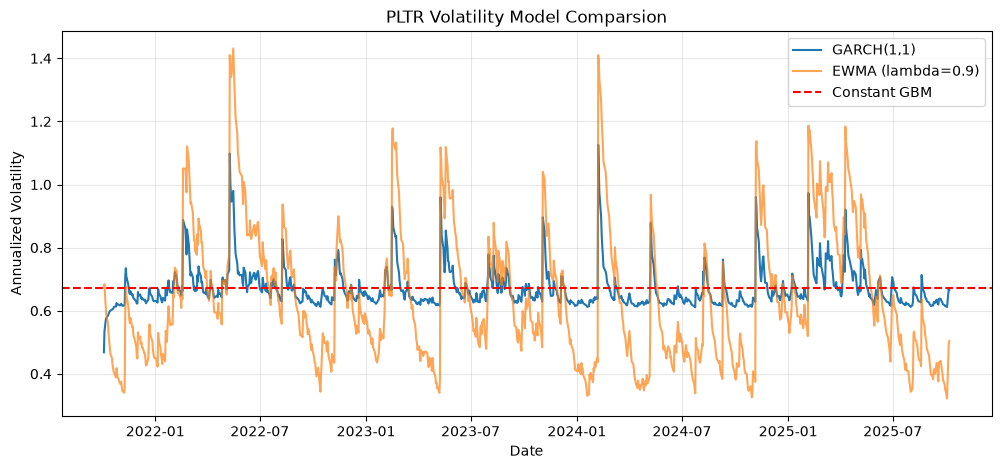

In [10]:
garch_vol = garch_fit.conditional_volatility
print(garch_vol.shape)
print(garch_vol[:5])
garch_annula_vol = garch_vol*np.sqrt(252)/100

## Visualization
plt.figure(figsize=(12,5))
plt.plot(
    calibration_return.index,
    garch_annula_vol,
    label = "GARCH(1,1)"
)
plt.plot(
    calibration_return.index,
    ewma_result[best_lambda],
    label = f"EWMA (lambda={best_lambda})",
    alpha =0.7
)
plt.axhline(
    annualized_histrocial_volatility_benchmark,
    color ="red",
    linestyle = "--",
    label = "Constant GBM"
)

plt.title("PLTR Volatility Model Comparsion")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

In [11]:
## GARCH Validation forecast
param = garch_fit.params

mu = param["mu"]
omega = param["omega"]
alpha = param["alpha[1]"]
beta = param["beta[1]"]
print(mu, omega,alpha, beta)

garch_validation_returns = validation_returns*100

garch_validation_variance = np.zeros(
    len(garch_validation_returns)
)

## Forecast for Validation date 1
garch_validation_variance[0] = (
    omega
    +alpha*(returns[-1]*100-mu)**2
    +beta*(garch_vol[-1])**2
)
# Forecast for Validation Day 2 onward
for t in range(1, len(garch_validation_returns)):
    garch_validation_variance[t] =(
        omega
        +alpha*(garch_validation_returns[t-1]-mu)**2
        +beta*garch_validation_variance[t-1]
    )

garch_validation_variance_decimal = (
    garch_validation_variance / 10000
)
print(garch_validation_variance_decimal.shape)
print(garch_validation_variance_decimal[:5])

garch_validation_mse = np.mean(
    (garch_validation_variance_decimal - validation_returns**2)**2
)

print("GARCH Validation MSE:", garch_validation_mse)


0.19626036363177338 3.5101812126353376 0.04870716302121454 0.756853643016407
(252,)
[0.00169066 0.00163215 0.00158974 0.00171559 0.00165264]
GARCH Validation MSE: 2.0526393603655128e-05


In [12]:
## Compare three models 
model_mse = {
    "Constant GBM": gbm_validation_mse,
    "EWMA" : ewma_validation_mse,
    "GARCH(1,1): ": garch_validation_mse
}
for model_name, mse in model_mse.items():
    print(model_name, mse)

best_model = min(model_mse, key=model_mse.get)
print("Best volatility forecast model:", best_model)

Constant GBM 2.0572226424633666e-05
EWMA 2.14021409352189e-05
GARCH(1,1):  2.0526393603655128e-05
Best volatility forecast model: GARCH(1,1): 


In [13]:
print("Calibration:", len(calibration_return))
print("Validation:", len(validation_return))
print("EWMA:", len(validation_emwa_variance))
print("GARCH:", len(garch_validation_variance_decimal))
print("Total:", len(log_return))

Calibration: 1007
Validation: 252
EWMA: 252
GARCH: 252
Total: 1259


In [14]:
assert len(validation_returns) == len(validation_emwa_variance)
assert len(validation_returns) == len(garch_validation_variance_decimal)

print("Validation observations:", len(validation_returns))
print("Best model:", min(model_mse, key=model_mse.get))

Validation observations: 252
Best model: GARCH(1,1): 


In [15]:
from pathlib import Path

data_dir = Path("../Data")
data_dir.mkdir(parents=True, exist_ok=True)

stock.to_csv(data_dir / "PLTR_stock_historical.csv")

print("Historical stock prices saved.")

Historical stock prices saved.
